**Mount Google drive and Extract the Data**     
 Instead of uploading the large CSV file everytime, we mounted the raw data on our google drive permanently to allow easy access anytime we decide to continue.
 we will now run the next cell to connect colab to our drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


*we need to verify if the data is indeed uploaded on our drive

In [2]:
!ls "/content/drive/MyDrive/Bank Project/Bank Data Set (Raw Data)/"

sample_submission.csv  test.csv  train.csv


LOADING DATA

  Now that we have located the dataset in google drive we load the three CSV files into panda data frame. We also print their shapes (rows, columns) to confirm everything has been read correctly before we start exploring.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



we will now define the exact path to our Dataset

In [4]:
data_path = '/content/drive/MyDrive/Bank Project/Bank Data Set (Raw Data)/'

we will then load the dataset using the path variables

In [5]:
train = pd.read_csv(data_path + 'train.csv')
test = pd.read_csv(data_path + 'test.csv')
sample = pd.read_csv(data_path + 'sample_submission.csv')

check dimension of the data

In [6]:
print("Train data shape:", train.shape)
print("Test data shape:", test.shape)
print("Sample submission shape:", sample.shape)

Train data shape: (750000, 18)
Test data shape: (250000, 17)
Sample submission shape: (250000, 2)


**LOOKING AT THE DATA **  
 Before building any models, we need to understand what we are working with. we will take reference from the Titanic nootebook from one of our previous seminar. we will start by looking at the first few roles to see the actual values and then use summary statistics to see the ranges and distributions of the numerical columns.

In [7]:
train.head()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,unknown,0
1,1,38,blue-collar,married,secondary,no,514,no,no,unknown,18,jun,185,1,-1,0,unknown,0
2,2,36,blue-collar,married,secondary,no,602,yes,no,unknown,14,may,111,2,-1,0,unknown,0
3,3,27,student,single,secondary,no,34,yes,no,unknown,28,may,10,2,-1,0,unknown,0
4,4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,unknown,1


SUMMARY STATISTICS   
 we will use describe() to see the mean, min, max and quartiles for numeric features. we will also check the text (cateregorical) columns to see the number of unique values they have.

summary staistics for numeric columns


In [8]:
print("--- Numeric Columns ---")
display(train.describe())

--- Numeric Columns ---


,id,age,balance,day,duration,campaign,pdays,previous,y
count,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000
mean,374999.500000,40.926395,1204.067397,16.117209,256.229144,2.577008,22.412733,0.298545,0.120651
std,216506.495284,10.098829,2836.096759,8.250832,272.555662,2.718514,77.319998,1.335926,0.325721
min,0.000000,18.000000,-8019.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,0.000000
25%,187499.750000,33.000000,0.000000,9.000000,91.000000,1.000000,-1.000000,0.000000,0.000000
50%,374999.500000,39.000000,634.000000,17.000000,133.000000,2.000000,-1.000000,0.000000,0.000000
75%,562499.250000,48.000000,1390.000000,21.000000,361.000000,3.000000,-1.000000,0.000000,0.000000
max,749999.000000,95.000000,99717.000000,31.000000,4918.000000,63.000000,871.000000,200.000000,1.000000


summary statistics for categorical columns

In [9]:
print("\n--- Categorical Columns ---")
obj_cols = train.select_dtypes(include='object').columns
display(train[obj_cols].describe())


--- Categorical Columns ---


,job,marital,education,default,housing,loan,contact,month,poutcome
count,750000,750000,750000,750000,750000,750000,750000,750000,750000
unique,12,3,4,2,2,2,3,12,4
top,management,married,secondary,no,yes,no,cellular,may,unknown
freq,175541,480759,401683,737151,411288,645023,486655,228411,672450


**Missing Values and Anomalies**    
 we will now check for missing values in both train and test.we will also lok for missing anomalies, such as (pdays = -1,) which means the client was not previously contacted.

In [10]:
print("Missing values in train:")
print(train.isna().sum())

print("\nMissing values in test:")
print(test.isna().sum())

Missing values in train:
id           0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Missing values in test:
id           0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
dtype: int64


check the hidden anomaly in pday

In [11]:
print(f"\nNumber of clients never contacted before (pdays = -1): {(train['pdays'] == -1).sum()}")


Number of clients never contacted before (pdays = -1): 672434


**Target Distribution**  
The target `y` is binary (1 = subscribed, 0 = did not). We will now  check the balance of the classes to see if there is an imbalance.

In [12]:
print("Target distribution in train:")
print(train['y'].value_counts(normalize=True).round(3) * 100, "%")

Target distribution in train:
y
0    87.9
1    12.1
Name: proportion, dtype: float64 %


**Findings on Missing Values and Anomalies**  
 There is **no explicit missing value** 'isna().sum()' confirms there are zero nulls in both the train and test sets.
 Hidden anomaly in pday: exactly 672,434 clients have a value of '-1' in 'pday'. in the original dataset documentation, -1 means the client was not previously contacted rather than "-1 days ago".

**Distribution of Numerical Features**  
we will histograms to see how the numerical features are distributed.this will help to locate skewed data or extreme outliers.

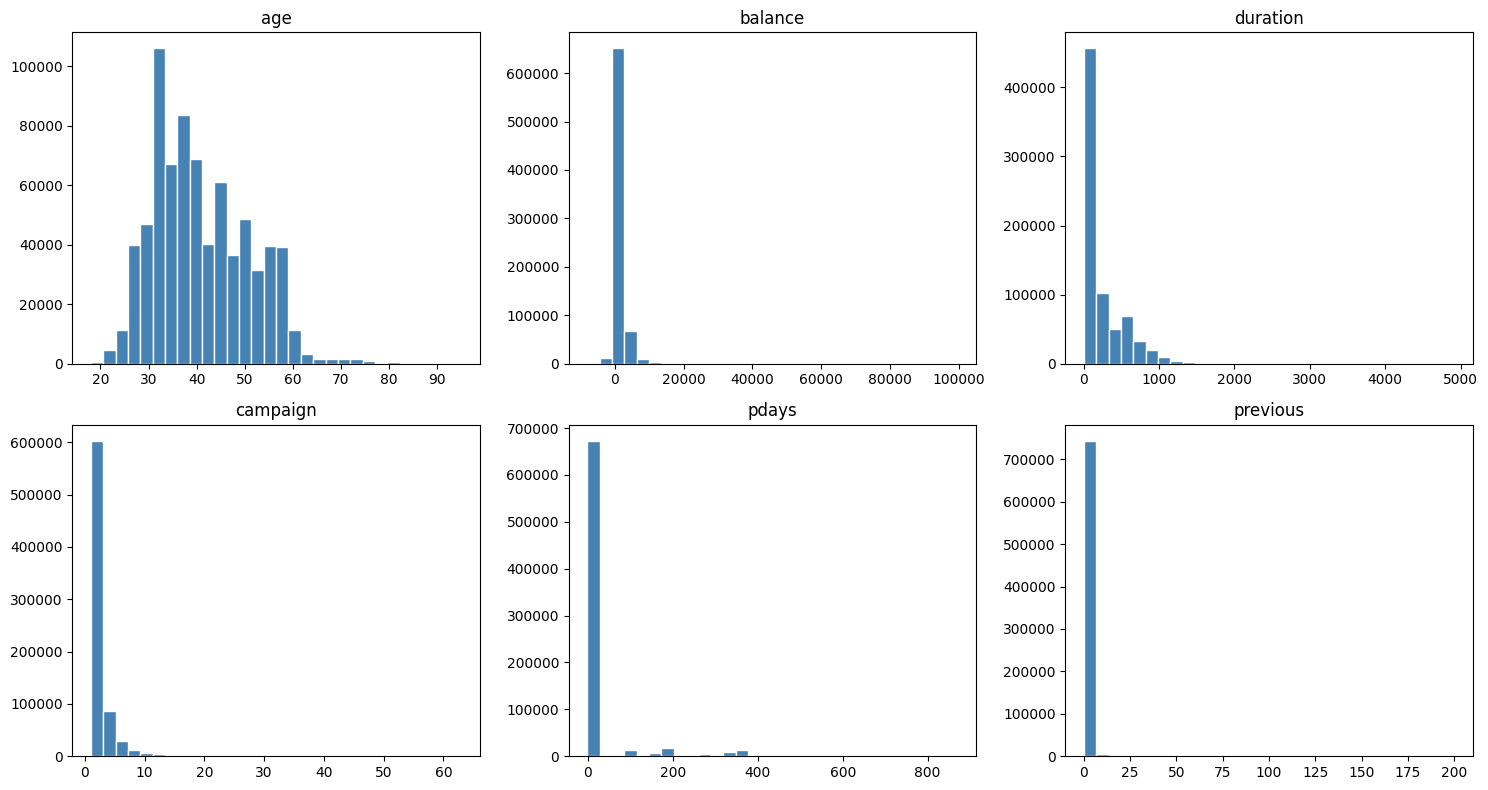

In [13]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    ax = axes[i//3, i%3]
    ax.hist(train[col].dropna(), bins=30, color='steelblue', edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.show()

Distribution of Categorical Features
  we will now use bar charts to see frequency of each category. this will tell us which group make the majority of clients.

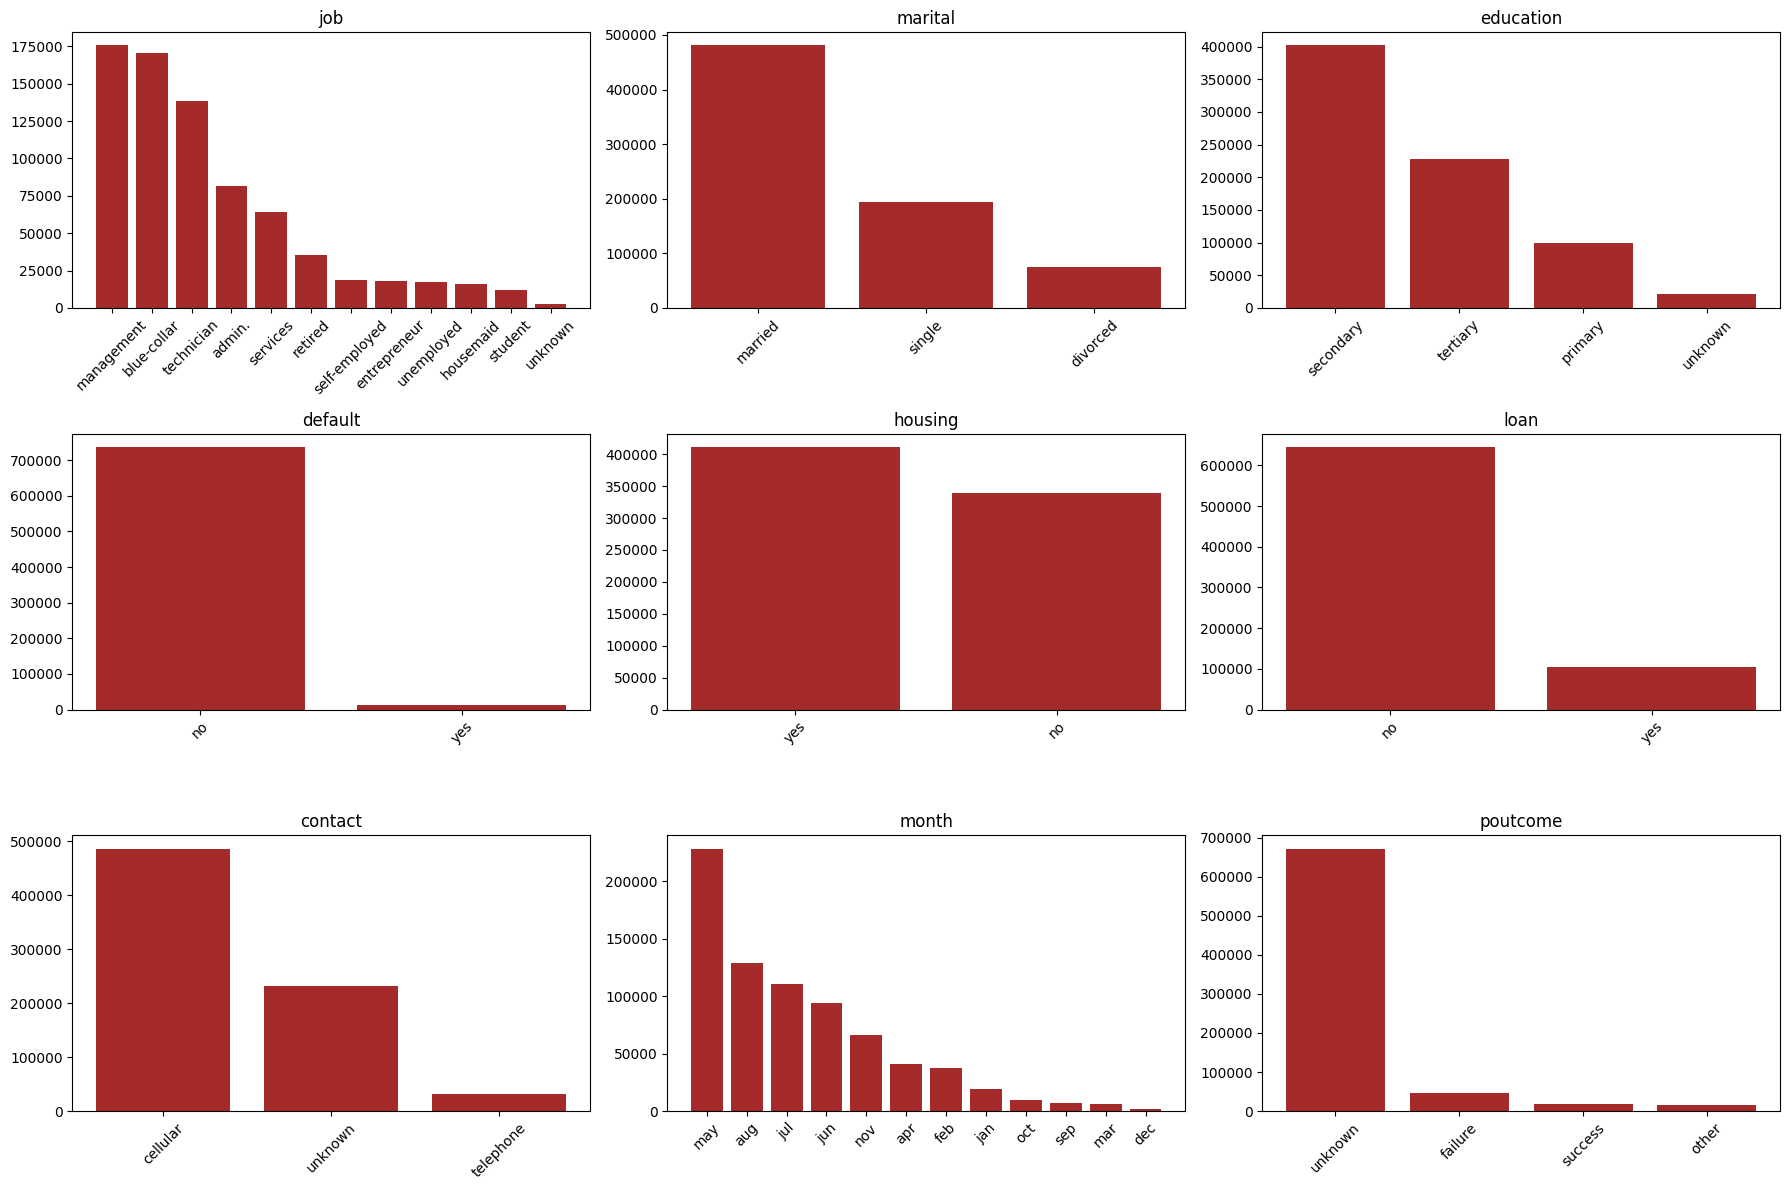

In [14]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for i, col in enumerate(cat_cols):
    ax = axes[i//3, i%3]
    counts = train[col].value_counts()
    ax.bar(counts.index.astype(str), counts.values, color='brown')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Relationship with the Target**  
 To see which features are useful, we plot the subscription rate (the mean of `y`) for each category.
The dashed line shows the overall average subscription rate (12.1%). If a category's bar is higher than the line, those clients are more likely to subscribe.

calculate the mean for y in each category

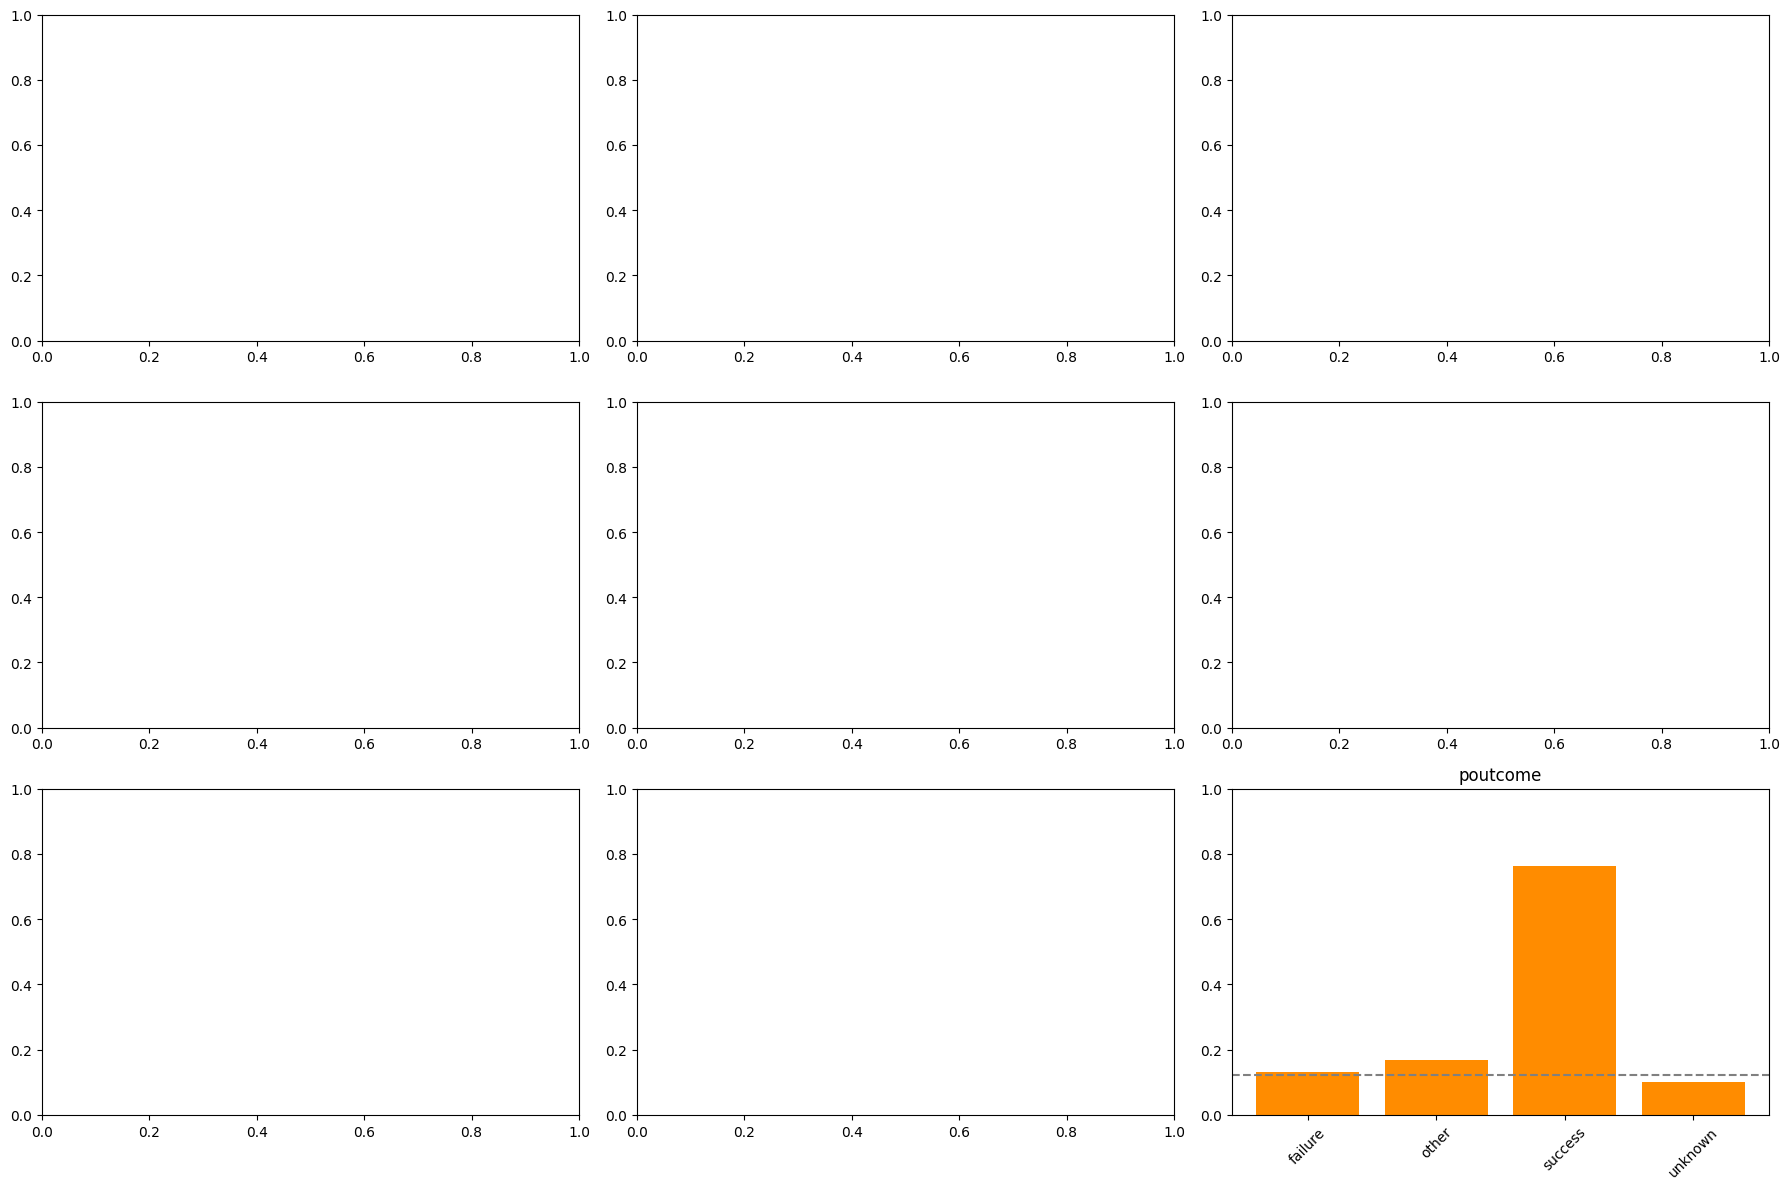

In [15]:
overall_rate = train['y'].mean()

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for i, col in enumerate(cat_cols):
    ax = axes[i//3, i%3]
rate = train.groupby(col)['y'].mean()
ax.bar(rate.index.astype(str), rate.values, color='darkorange')
ax.axhline(overall_rate, color='gray', linestyle='--')
ax.set_ylim(0, 1)
ax.set_title(col)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()



**Findings from the Relationship with the target**  
 Looking at the orange bar charts, we can draw several conclusions:
 **The strongest predictor is `poutcome`:** Clients whose previous campaign outcome was "success" have a massive subscription rate of nearly 80%, compared to the 12% average.
 **Months matter:** The success rate varies heavily by month. Calls in March, September, October, and December are much more successful than the massive volume of calls in May.
 **Job and Education:** Students and retired clients have higher subscription rates than blue-collar workers.

**Preprocessing and Feature Engineering**
Based on our EDA, we need to handle the `pdays` anomaly and create some new features to help the model.
We will build the following new features:
1. **`pdays_clean` and `pdays_flag`:** We replace `-1` with NaN, and create a flag to tell the model which clients were never contacted before.
2. **`duration_log`:** The call duration is highly skewed. A log transformation makes it easier for the model to learn.
3. **`month_num`:** We convert the month names into numbers (1-12) so the model understands the chronological order.

we will create copies so we don't accidentally mess up the original data

In [16]:

train_fe = train.copy()
test_fe = test.copy()


months = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
          'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}

for df in [train_fe, test_fe]:

    df['pdays_flag'] = (df['pdays'] == -1).astype(int)
    df['pdays_clean'] = df['pdays'].replace(-1, np.nan)


    df['duration_log'] = np.log1p(df['duration'])


    df['month_num'] = df['month'].map(months)


cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
for col in cat_cols:
    train_fe[col] = train_fe[col].astype('category')
    test_fe[col] = test_fe[col].astype('category')

print("Feature engineering and type conversion complete!")

Feature engineering and type conversion complete!


**Baseline and Model Training**   
 Before training a complex model, we establish a baseline (predicting all 0s).
We then train a LightGBM model using 5-Fold Stratified Cross-Validation.

In [17]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb


target = 'y'
features = [c for c in train_fe.columns if c not in ['id', target]]

X = train_fe[features]
y = train_fe[target]
X_test = test_fe[features]


params = {
    'objective': 'binary', 'metric': 'auc', 'boosting_type': 'gbdt',
    'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1,
    'random_state': 42, 'n_jobs': -1, 'verbose': -1
}


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

print("Starting training... (This will take a few minutes)")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**params, n_estimators=1000)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='auc',
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
        categorical_feature=cat_cols
    )

    oof_preds[val_idx] = model.predict_proba(X_val)[:, 1]
    test_preds += model.predict_proba(X_test)[:, 1] / skf.n_splits

    fold_auc = roc_auc_score(y_val, oof_preds[val_idx])
    print(f"Fold {fold+1} ROC-AUC: {fold_auc:.5f}")

overall_auc = roc_auc_score(y, oof_preds)
print(f"\nOverall Out-of-Fold (OOF) ROC-AUC: {overall_auc:.5f}")

Starting training... (This will take a few minutes)
Fold 1 ROC-AUC: 0.96881
Fold 2 ROC-AUC: 0.96785
Fold 3 ROC-AUC: 0.96783
Fold 4 ROC-AUC: 0.96891
Fold 5 ROC-AUC: 0.96816

Overall Out-of-Fold (OOF) ROC-AUC: 0.96831


**Submission**  
 we will now format our test set predictions into the required kaggle format

In [18]:

submission = pd.DataFrame({'id': sample['id'], 'y': test_preds})

submission.to_csv('submission.csv', index=False)
print("Submission file created successfully!")

submission.head()

Submission file created successfully!


,id,y
0,750000,0.002174
1,750001,0.087377
2,750002,0.000218
3,750003,0.000046
4,750004,0.022096


In [19]:
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Logistic Regression**

We will train a Logistic Regression model because we will be testing different model types. It is a linear model and will not be able to read text columns directly, so we will convert our categorical features to a one-hot format using `pd.get_dummies()`.

Logistic Regression doesn't handle missing values (`NaN`) and will fill the missing values with the median value. Moreover, our scale of numerical features differ significantly (also age, balance etc.), so the model is hard to converge. To address the ConvergenceWarning, and aid in proper learning of the model, we normalize the data with `StandardScaler`.

Same 5-fold cross-validations will be used.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler


X_logreg = pd.get_dummies(X, drop_first=True)
X_test_logreg = pd.get_dummies(X_test, drop_first=True)


X_test_logreg = X_test_logreg.reindex(columns = X_logreg.columns, fill_value=0)


X_logreg = X_logreg.fillna(X_logreg.median())
X_test_logreg = X_test_logreg.fillna(X_test_logreg.median())


scaler = StandardScaler()
X_logreg_scaled = scaler.fit_transform(X_logreg)
X_test_logreg_scaled = scaler.transform(X_test_logreg)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_logreg = np.zeros(len(X))
test_preds_logreg = np.zeros(len(X_test))

print("Training Logistic Regression...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_logreg_scaled, y)):
    X_tr, X_va = X_logreg_scaled[train_idx], X_logreg_scaled[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]


    model = LogisticRegression(max_iter=500, random_state=42)
    model.fit(X_tr, y_tr)

    oof_logreg[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds_logreg += model.predict_proba(X_test_logreg_scaled)[:, 1] / skf.n_splits

print(f"Logistic Regression OOF ROC-AUC: {roc_auc_score(y, oof_logreg):.5f}")

Training Logistic Regression...
Logistic Regression OOF ROC-AUC: 0.94408


**Random Forest(Bagging Model)**

A Random Forest is a collection of parallel decision trees. In Titanic notebook, we saw that the text columns were converted to numbers by using pd.get_dummies(). We attempted to pass the pandas types directly, but got a `ValueError` exception from scikit-learn's Random Forest.

For this model, we are going to again use the function `pd.get_dummies()` to solve the issue. Unlike Logistic Regression, tree based models are not affected by the scale of the features so we don't have to scale data. We will be employing the same Cross-Validation technique of 5-fold.

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score


X_rf = pd.get_dummies(X, drop_first=True)
X_test_rf = pd.get_dummies(X_test, drop_first=True)


X_test_rf = X_test_rf.reindex(columns = X_rf.columns, fill_value=0)


X_rf = X_rf.fillna(X_rf.median())
X_test_rf = X_test_rf.fillna(X_test_rf.median())

oof_rf = np.zeros(len(X))
test_preds_rf = np.zeros(len(X_test))

print("Training Random Forest... (This may take a few minutes)")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_rf, y)):
    X_tr, X_va = X_rf.iloc[train_idx], X_rf.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]


    model = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)

    oof_rf[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds_rf += model.predict_proba(X_test_rf)[:, 1] / skf.n_splits

print(f"Random Forest OOF ROC-AUC: {roc_auc_score(y, oof_rf):.5f}")

Training Random Forest... (This may take a few minutes)
Random Forest OOF ROC-AUC: 0.95692


**Hyperparemeter Tunning with RandomizedsearchCV**

We will use `RandomizedSearchCV` to find the most optimal values for the following parameters for our LightGBM model: `learning_rate`, `num_leaves`, and `n_estimators`. To save time, 3-Fold Cross-Validation will be used in this tuning phase and then the best parameters obtained will be compared to the original LightGBM parameters.

In [22]:
from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb


param_grid = {
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 63, 127],
    'n_estimators': [100, 300, 500]
}


lgb_tune = lgb.LGBMClassifier(objective='binary', random_state=42, n_jobs=-1, verbose=-1)


random_search = RandomizedSearchCV(
    estimator=lgb_tune,
    param_distributions=param_grid,
    n_iter=5,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning (This will take a few minutes)...")


random_search.fit(X, y, categorical_feature=cat_cols)

print(f"\nBest Parameters Found: {random_search.best_params_}")
print(f"Best Cross-Validation Score: {random_search.best_score_:.5f}")

Starting Hyperparameter Tuning (This will take a few minutes)...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best Parameters Found: {'num_leaves': 127, 'n_estimators': 300, 'learning_rate': 0.1}
Best Cross-Validation Score: 0.96784


Final Model Comparison

Below is the summary of the validation scores for the Baseline, Logistic Regression, Random Forest and LightGBM. As we can see that LightGBM model has the best performance score, hence we selected it for our final submission.

In [23]:

results_df = pd.DataFrame({
    'Model': ['Baseline (Predict 0)', 'Logistic Regression', 'Random Forest', 'LightGBM'],
    'OOF ROC-AUC': [0.50000, roc_auc_score(y, oof_logreg), roc_auc_score(y, oof_rf), 0.96831]
})


results_df = results_df.sort_values(by='OOF ROC-AUC', ascending=False)
print(results_df.to_string(index=False))

               Model  OOF ROC-AUC
            LightGBM     0.968310
       Random Forest     0.956923
 Logistic Regression     0.944085
Baseline (Predict 0)     0.500000


In [24]:
submission_new = pd.DataFrame({'id': sample['id'], 'y': test_preds})

submission_new.to_csv('submission_final.csv', index=False)
print("New submission file 'submission_final.csv' created successfully!")

New submission file 'submission_final.csv' created successfully!


In [25]:
from google.colab import files
files.download('submission_final.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>